[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/18_whitening_samples.ipynb)

# Whitening: images generated by the model of the whitened images

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Use the diffusion model of the whitened images (notebook 16) as an image generator: start from pure noise and denoise step by step, and look at the images it generates; then, for a few of them, how the model builds each one, step by step.

* **Requirements**: the model of the whitened images (`runs/diffusion/unconditional/tinyimagenet-whitened/`, notebook 16), a GPU, and `multigeom` from the `g-per-scale` branch.

* **Time**: about a minute on a GPU.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub: on Google Colab always (with `diffusers`), elsewhere only if the installed one lacks its functions.

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install that branch only if the installed multigeom lacks its
# functions (this replaces an editable install; restart the kernel afterwards)
else:
    import multigeom

    if not hasattr(multigeom.analysis, "compute_bootstrap"):
        %pip install -q --no-deps {BRANCH}
        print("installed multigeom from the g-per-scale branch: restart the kernel")

CPU times: user 3.12 s, sys: 102 ms, total: 3.22 s
Wall time: 614 ms


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the model, the number of samples, the seed, and where the figure goes.

<details><summary>Details</summary>

* `sample_images` generates images from pure noise with the DDPM sampler the model was trained for, using its null token (the unconditional model); `plot_samples` draws them on a grid. With `keep`, `sample_images` also returns the noisy image $x_t$ and the denoised image $\hat x(x_t)$ at chosen steps; `WhiteningFilter.invert` un-whitens images, and `plot_recovered` draws a trajectory, both as in notebook 17.

</details>

In [2]:
%%time

import os
from pathlib import Path

import torch

# move to the repository root (the folder containing environment.yml): runs/ and
# assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import WhiteningFilter
from multigeom.diffusion import sample_images
from multigeom.diffusion.model import build_diffusion_model, build_scheduler
from multigeom.plotting import plot_recovered, plot_samples
from multigeom.utils import get_device

# the parameters of this notebook
PARAMS = {
    # the model of the whitened images (notebook 16)
    "whitened_model": "runs/diffusion/unconditional/tinyimagenet-whitened",
    # the number of samples (a square number, for the grid), and the seed of the noise
    "n_samples": 16,
    "seed": 0,
    # the trajectories: the samples drawn (their places on the grid, row by row), the
    # DDPM steps kept (those of notebook 17), the whitening filter of notebook 16 and
    # the regularisation of its inverse (that of notebook 17)
    "trajectory_samples": [1, 5, 8, 10, 14],
    "trajectory_steps": [950, 800, 700, 600, 500, 400, 300, 200, 100, 40, 20, 5],
    "filter": "data/02_intermediate/16_whitening/filter.pt",
    "regularization": 1e-3,
    # where the figure is saved, and its resolution in the file and on screen
    "figure_dir": "assets/figures/whitening_samples",
    "file_dpi": 200,
    "screen_dpi": 100,
}

# the diffusion config (packaged with multigeom), and the device
diff_cfg = load_config("diffusion")
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 1.06 s, sys: 148 ms, total: 1.21 s
Wall time: 1.22 s


## 2. Load the model of the whitened images

Trained by `scripts/train_whitened_diffusion.py` (notebook 16).

In [3]:
%%time

model_dir = Path(PARAMS["whitened_model"])
unet = build_diffusion_model(diff_cfg).to(device)
stored = torch.load(
    model_dir / "final_model.pt", map_location=device, weights_only=False
)
unet.load_state_dict(stored["model_state_dict"])
unet.eval()
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)

CPU times: user 288 ms, sys: 182 ms, total: 470 ms
Wall time: 475 ms


## 3. Generate and plot the samples

Start from pure noise and run the 1,000 DDPM steps backwards with the null token. The samples are drawn on one gray scale from $-m$ to $m$, $m$ the 99.5th percentile of their $|$values$|$, and saved to `assets/figures/whitening_samples/samples.png`. The same run keeps, at the steps of `PARAMS["trajectory_steps"]`, the noisy and the denoised images of every sample, for section 4.

pixel values: std 0.50, range -3.08 to 3.50
CPU times: user 9.24 s, sys: 4.37 s, total: 13.6 s
Wall time: 13.3 s


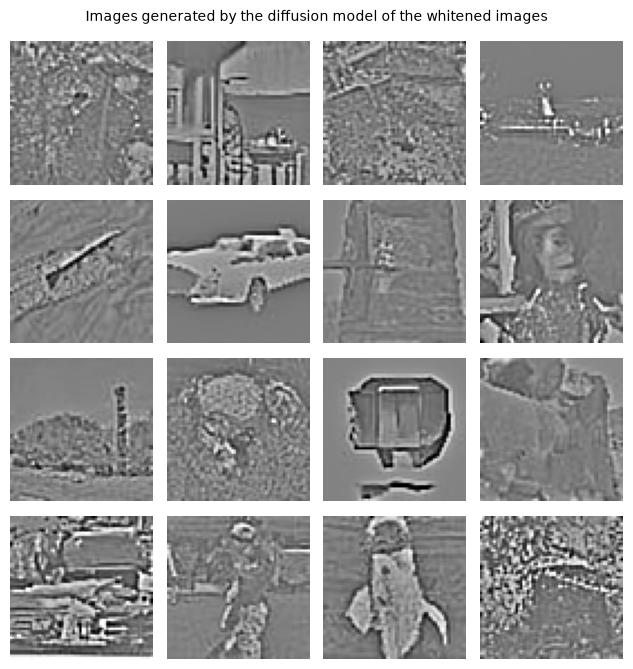

In [4]:
%%time

# 1. the samples, from seeded noise
generator = torch.Generator(device=device).manual_seed(PARAMS["seed"])
size = diff_cfg.unet.image_size
shape = (PARAMS["n_samples"], 1, size, size)
samples, trajectory = sample_images(
    unet, alphas_cumprod, shape, device, generator, keep=PARAMS["trajectory_steps"]
)
samples = samples.cpu()

# 2. the figure, also saved
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
title = "Images generated by the diffusion model of the whitened images"
fig, _ = plot_samples(samples, title, PARAMS)
fig.savefig(figure_dir / "samples.png", dpi=PARAMS["file_dpi"], bbox_inches="tight")
low, high = float(samples.min()), float(samples.max())
print(f"pixel values: std {samples.std():.2f}, range {low:.2f} to {high:.2f}")

## 4. How the model builds a sample, step by step

For 5 of the samples, the generation from pure noise (left) to the sample (right), at 12 of its 1,000 steps, in the layout of notebook 17: the noisy image $x_t$ at that step (top), the model's guess of the final image $\hat x(x_t)$ (middle), and that guess un-whitened with the inverse of the whitening filter (bottom). The left column has the final sample and the sample un-whitened. One figure per sample, saved to `assets/figures/whitening_samples/trajectory_<n>.png`, $n$ its place on the grid.

<details><summary>Details</summary>

* The columns are one run of the sampler, not independent noisy versions as in notebook 17. The noise scale of each step is $\tau = \log t$, $t = (1 - \bar\alpha)/\bar\alpha$.
* Gray scales as in notebook 17: whitened images on that of the sample, un-whitened ones on that of the sample un-whitened, each noisy image on its own.

</details>

5 figures saved in assets/figures/whitening_samples
CPU times: user 3.1 s, sys: 50.2 ms, total: 3.15 s
Wall time: 2.03 s


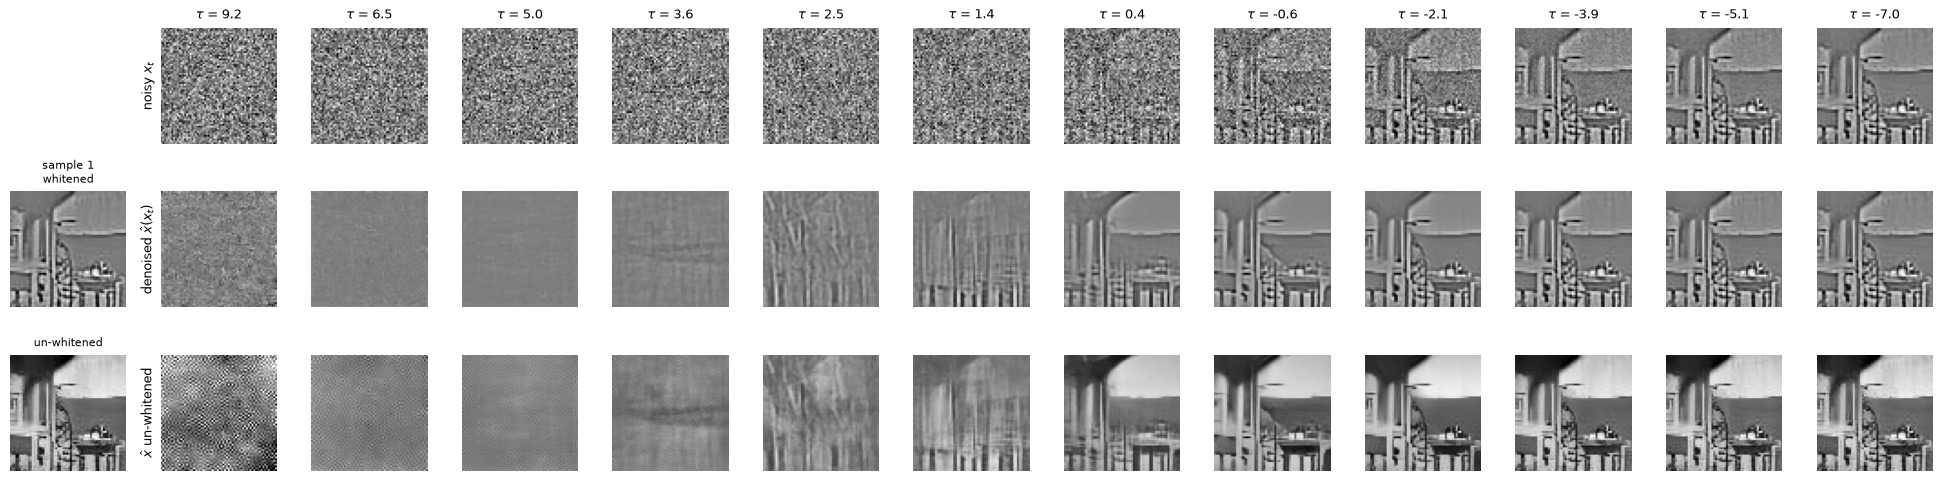

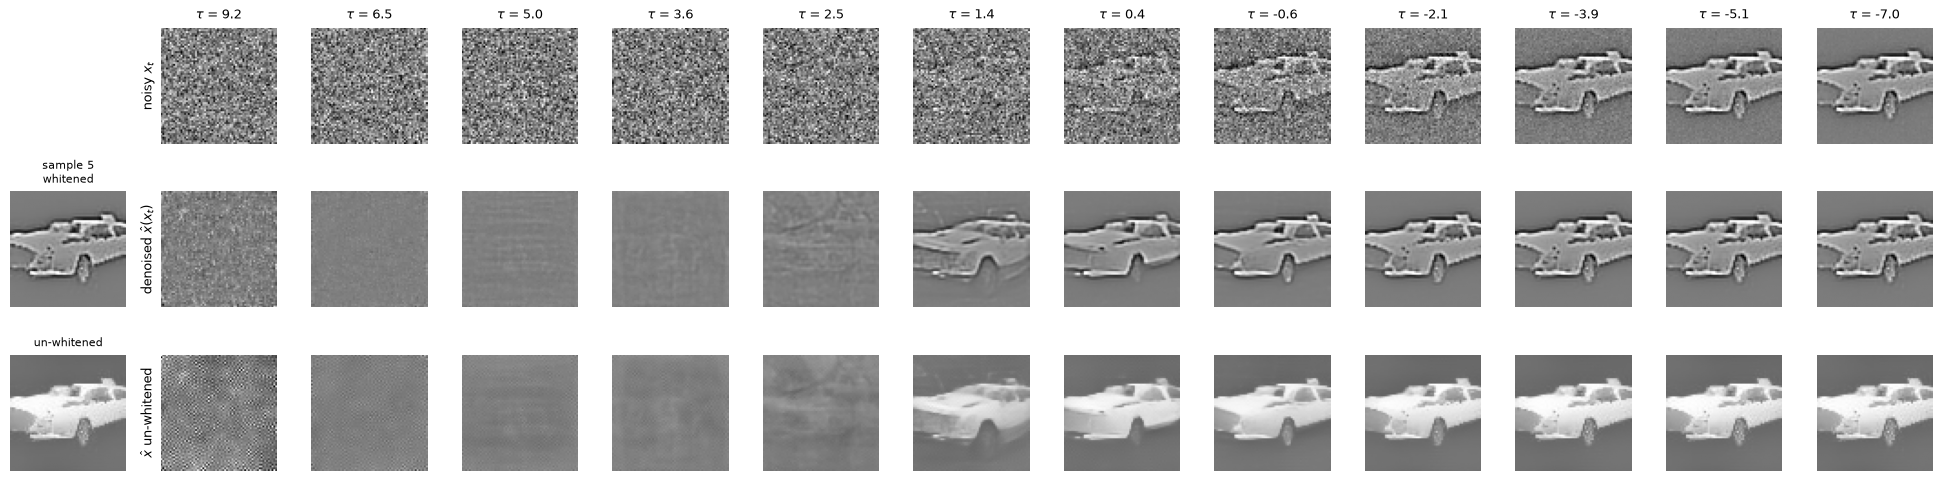

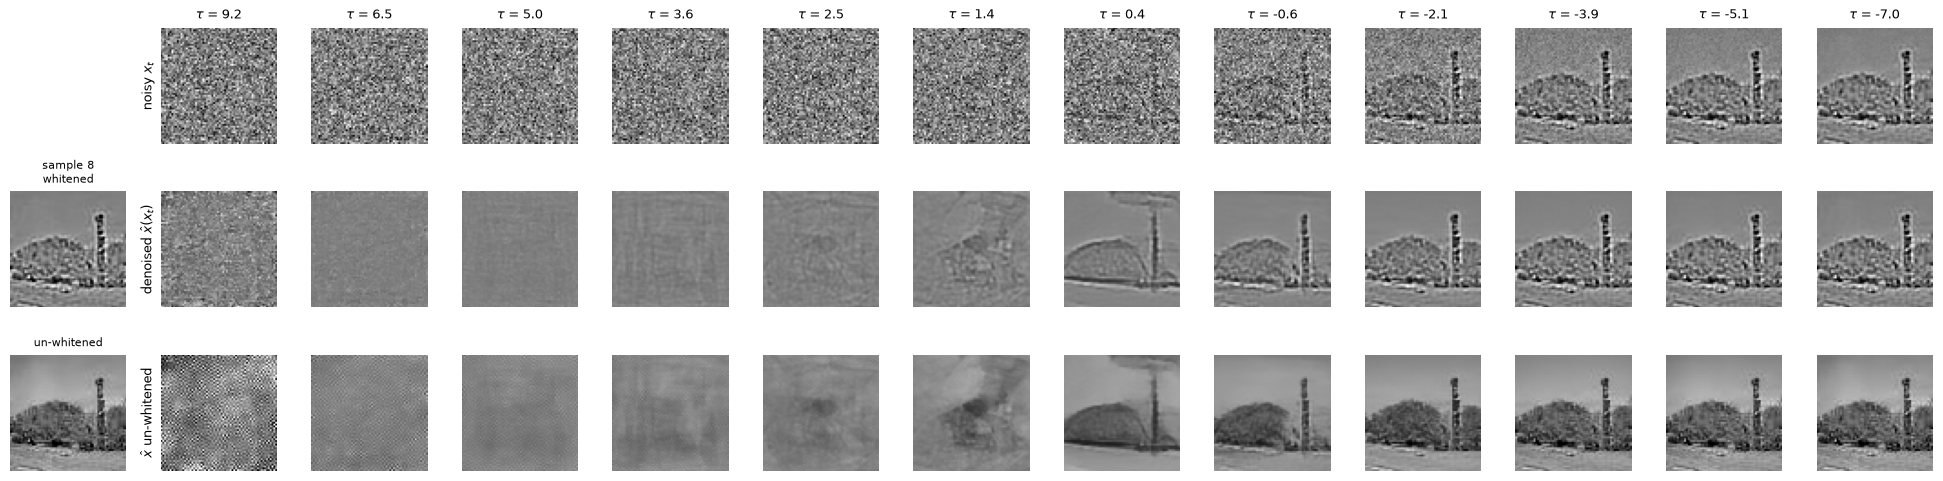

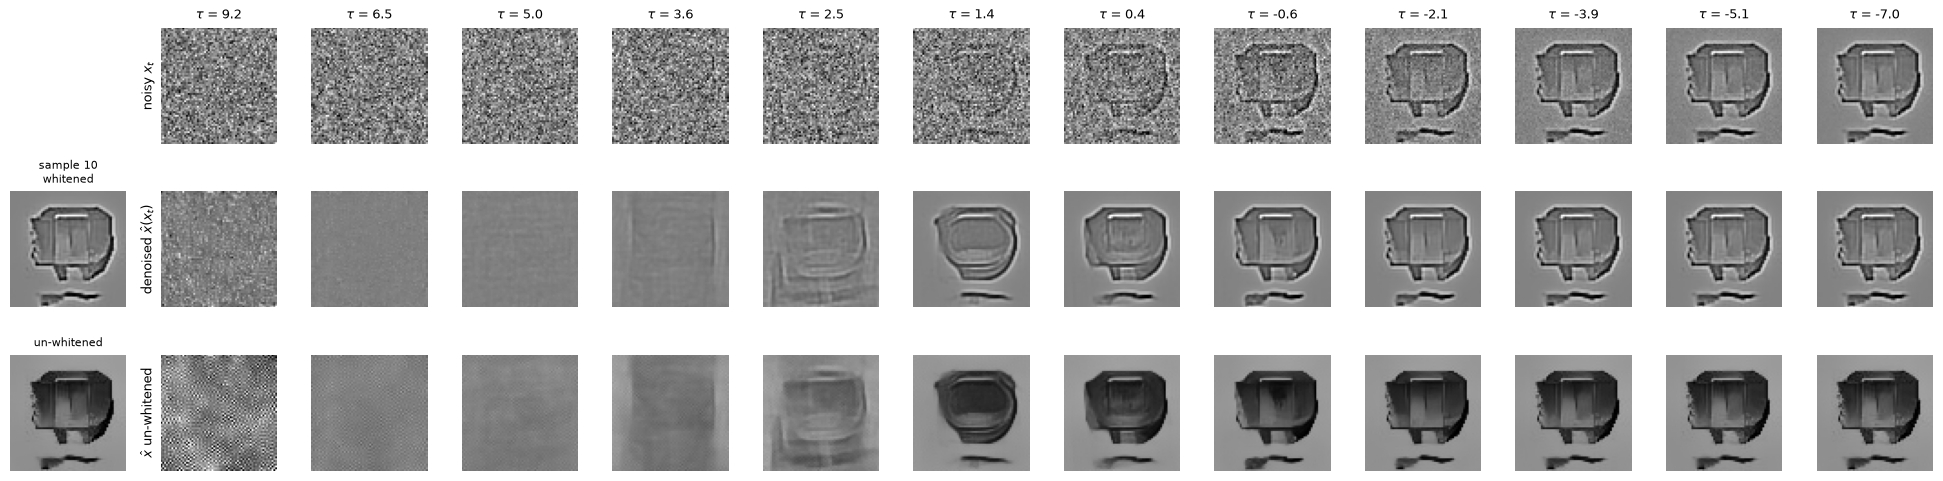

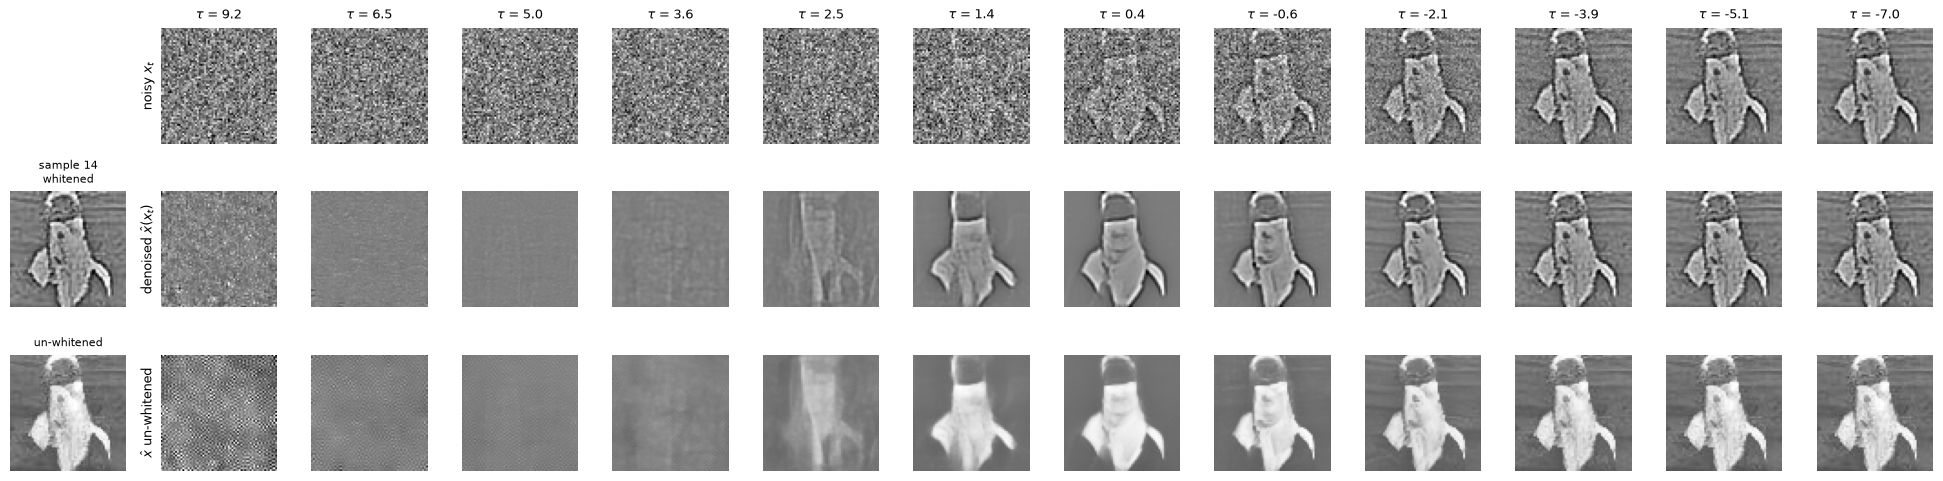

In [5]:
%%time

# 1. the whitening filter of notebook 16
whitening = WhiteningFilter.from_state_dict(torch.load(PARAMS["filter"]))
regularization = PARAMS["regularization"]

# 2. one figure per sample: at each kept step, x_t, x̂(x_t) and x̂ un-whitened
for n in PARAMS["trajectory_samples"]:
    sample = samples[n : n + 1]
    rows = {}
    for t_j, (noisy, denoised) in trajectory.items():
        ab = alphas_cumprod[t_j]
        scale = float(((1 - ab) / ab).log())
        x_hat = denoised[n : n + 1]
        rows[scale] = (noisy[n : n + 1], x_hat, whitening.invert(x_hat, regularization))
    fig, _ = plot_recovered(
        None,
        sample,
        whitening.invert(sample, regularization),
        rows,
        f"sample {n}",
        PARAMS,
        labels=("whitened", "un-whitened"),
    )
    fig.savefig(
        figure_dir / f"trajectory_{n}.png", dpi=PARAMS["file_dpi"], bbox_inches="tight"
    )
print(len(PARAMS["trajectory_samples"]), "figures saved in", figure_dir)

## 5. Conclusion

* **What we computed.** 16 images generated from pure noise by the diffusion model of the whitened images, with the 1,000 DDPM steps and its null token (about 13 s on one GPU), and the trajectories of 5 of them. The figures are in `assets/figures/whitening_samples/`.
* **The samples look like whitened images.** Edge maps on a uniform gray background, with light–dark double outlines along edges, as the whitened examples of notebook 16: no overall brightness or shading.
* **Some show recognisable structure**: a car, a building with windows, a figure, a horizon with a tower; others are textures (foliage, ground). As usual for TinyImageNet models at 64 x 64, objects are plausible in layout rather than in detail.
* **Their pixel values have heavy tails** (standard deviation 0.50, range −3.1 to 3.5), as the whitened images, of which 7.4% fall outside [−1, 1] (notebook 16).
* **The model builds a sample from coarse to fine.** On the car (sample 5) and the figure (sample 14): up to $\tau \approx 3.6$ its guess $\hat x(x_t)$ is a nearly uniform gray; a blurred silhouette appears around $\tau = 2.5$; the object's layout and main edges are set by $\tau \approx 1.4$; from there on, the steps only sharpen edges and add fine texture, and the guess barely changes below $\tau \approx -2$. At the coarsest step ($\tau = 9.2$) the un-whitened guess is a checkerboard-like grain, as in notebook 17.